# El costo invisible de la fertilidad: la segunda jornada en el hogar

**Construcción de bases y figuras** — Exploraciones sobre Pobreza, Desarrollo Humano y Políticas Sociales (UdeSA, 2025).

Este notebook:
1. arma las bases de análisis a partir de la EDER-CABA 2019 (`couples.csv`, `couples_panel.csv`, `women_panel.csv`), que luego usa `programs/stata/regresiones.do`;
2. calcula las estadísticas descriptivas citadas en el texto;
3. genera las figuras del trabajo (numeradas igual que en el PDF).

**Datos de entrada:** los archivos de la EDER 2019 tienen que estar en la carpeta `data/` en la raíz del proyecto (ver `README.md`).

In [1]:
# importamos paquetes
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# directorios (rutas relativas a la raíz del proyecto)
ROOT = Path.cwd().resolve()
while not (ROOT / 'programs').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

DATA = ROOT / 'data'
OUT_DATA = ROOT / 'output' / 'data'
OUT_FIG = ROOT / 'output' / 'figures'
OUT_TAB = ROOT / 'output' / 'tables'
for d in [OUT_DATA, OUT_FIG, OUT_TAB]:
    d.mkdir(parents=True, exist_ok=True)

In [3]:
# importamos bases
data = pd.read_csv(DATA / 'eder2019_usuarios_retro.txt', sep='\t', encoding='utf-16')
people = pd.read_csv(DATA / 'eder2019_usuarios_personas.txt', sep='\t', encoding='utf-16')
spouses = pd.read_csv(DATA / 'eder2019_usuarios_retro_conyuge.txt', sep='\t', encoding='utf-16')
children = pd.read_csv(DATA / 'eder2019_usuarios_retro_hijo.txt', sep='\t', encoding='utf-16')

## 1) Armamos las bases

In [4]:
# limpiezas y correcciones
spouses['p8_6'] = spouses['p8_6'].map({1: 0, 2: 1})        # corresidencia conyugal: 1 = conviven
data['p5_2'] = data['p5_2'].replace(2, 1)                   # trabajo: 1 = trabaja (nuevo trabajo o cambio dentro del mismo)
data['p6_3'] = data['p6_3'].replace(0, 3)                   # tareas domésticas: quienes nunca las realizaron se agrupan en "ayuda externa"
# informalidad: trabaja y no le descontaban ni aportaba para la jubilación
data['informality'] = np.where(data['p5_2'] > 0, (data['p5_9'] == 3).astype(int), np.nan)
children = children.drop(['operativo'], axis=1)

/tmp/ipykernel_283/2590284584.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data['informality'] = np.where(data['p5_2'] > 0, (data['p5_9'] == 3).astype(int), np.nan)


In [5]:
# definimos función para crear id individuo
def create_id(df):
    df['individual_id'] = ('id_' + df['id'].astype(str) + '_' + df['nhogar'].astype(str) + '_' + df['miembro'].astype(str))
    return df

In [6]:
# creamos ids de individuo, año (persona en cada año), pareja e hijo
for df in [data, people, spouses, children]:
    create_id(df)

data['year_id'] = data['individual_id'].astype(str) + '_' + data['annio_retro'].astype(str)
spouses['spouse_id'] = spouses['individual_id'].astype(str) + '_' + spouses['conyuge'].astype(str)
spouses['spouse_year_id'] = spouses['individual_id'].astype(str) + '_' + spouses['annio_retro'].astype(str)
spouses['year_id'] = spouses['individual_id'].astype(str) + '_' + spouses['annio_retro'].astype(str)
children['child_id'] = children['individual_id'].astype(str) + '_' + children['hijo'].astype(str)

/tmp/ipykernel_283/4071885356.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['individual_id'] = ('id_' + df['id'].astype(str) + '_' + df['nhogar'].astype(str) + '_' + df['miembro'].astype(str))


/tmp/ipykernel_283/632238404.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data['year_id'] = data['individual_id'].astype(str) + '_' + data['annio_retro'].astype(str)


In [7]:
# creamos dataset de mujeres entrevistadas (encuesta retrospectiva, sexo = mujer)
women = people[(people['retro'] == 1) & (people['p2'] == 2)].copy()
women = women.drop(['operativo', 'retro', 'fexp'], axis=1)

In [8]:
# definimos función para agregar por moda
def safe_mode(x):
    m = x.mode()
    return m.iloc[0] if not m.empty else np.nan

In [9]:
# agregamos información a la base: cohorte, cantidad de hijos, trabajo y tareas domésticas (moda)
agg_dict = {'cohorte': 'first', 'p10_1': 'first', 'p14_6': 'first', 'p5_2': safe_mode, 'p6_3': safe_mode}
individuals = data.groupby('individual_id', as_index=False).agg(agg_dict)
women = pd.merge(women, individuals, on=['individual_id'], how='inner')

In [10]:
# creamos dummy 'mother'
women['mother'] = (women['p10_1'] > 0).astype(int)

In [11]:
# agregamos cantidad de parejas
last_spouses = spouses.groupby('individual_id', as_index=False).agg('last')
women = pd.merge(women, last_spouses[['individual_id', 'conyuge']], on='individual_id', how='left')
women['conyuge'] = women['conyuge'].fillna(0).astype(int)

In [12]:
# nivel educativo: estimamos utilizando último nivel educativo completo
def assign_education(row):
    nivel = row['e12a']
    completo = row['e13']

    if nivel in [0, 99] or pd.isna(nivel):
        return 1

    if completo == 1:
        if nivel in [3, 4, 5, 6, 15]:   # primario
            return 2
        elif nivel in [7, 10]:          # secundario
            return 3
        elif nivel in [12, 13]:         # terciario / universitario
            return 4
        elif nivel == 14:               # posgrado
            return 5
    else:
        if nivel in [3, 4, 5, 6, 15]:
            return 1
        elif nivel in [7, 10]:
            return 2
        elif nivel in [12, 13]:
            return 3
        elif nivel == 14:
            return 4

    return 1

women['education'] = women.apply(assign_education, axis=1)

In [13]:
# creamos tipo de unión 'noviazgo' (= 10): el año previo a que empiece la unión formal (tipo de unión 1-4)
all_spouses = spouses[spouses['individual_id'].isin(women['individual_id'])].copy()
p8_3 = []
last_zero = False
previous_spouse = None

for _, row in all_spouses.iterrows():
    if row['spouse_id'] != previous_spouse:   # no arrastramos el estado entre parejas distintas
        last_zero = False
    if row['p8_3'] == 0:
        last_zero = True
    elif row['p8_3'] in [1, 2, 3, 4] and last_zero:
        last_zero = False
        p8_3[-1] = 10
    else:
        last_zero = False
    p8_3.append(row['p8_3'])
    previous_spouse = row['spouse_id']

all_spouses['p8_3'] = p8_3
all_spouses['p8_6'] = all_spouses['p8_6'].fillna(0).astype(int)

In [14]:
# asignamos a cada hijo la pareja con la que convivía la madre el año de su nacimiento
all_children = children.drop_duplicates(subset='child_id', keep='first')
all_children = all_children[all_children['individual_id'].isin(women['individual_id'])].copy()
father_id = []

for _, row in all_children.iterrows():
    if row['p10_2b'] == 9999:
        father_id.append(9999)
        continue
    children_year_id = row['individual_id'] + '_' + str(row['p10_2b'])
    try:
        father_id.append(all_spouses.loc[(all_spouses['spouse_year_id'] == children_year_id) &
                                         (all_spouses['p8_3'].isin([1, 2, 3, 4, 10])), 'spouse_id'].iloc[0])
    except IndexError:
        father_id.append(0)

all_children['father_id'] = father_id

In [15]:
# agregamos en qué año se volvieron madres y a qué edad
first_child = all_children.sort_values('p10_2b').drop_duplicates(subset='individual_id', keep='first')
women = pd.merge(women, first_child[['individual_id', 'p10_2b']], on='individual_id', how='left')
women['p10_2b'] = women['p10_2b'].replace(9999, np.nan)
women['age_motherhood'] = women['p10_2b'] - women['p3']

In [16]:
# creamos variable fathers_count
fathers_per_mother = all_children.groupby('individual_id')['father_id'].nunique().reset_index(name='fathers_count')
women = women.merge(fathers_per_mother, on='individual_id', how='left')
women['fathers_count'] = women['fathers_count'].fillna(0).astype(int)

In [17]:
# categorías de historias de vida: single partner fertility, repartnered y multipartner fertility
women['multipartner'] = (women['conyuge'] > 1).astype(int)
women['single_partner'] = ((women['multipartner'] == 0) & (women['fathers_count'] <= 1)).astype(int)
women['repartnered'] = ((women['multipartner'] == 1) & (women['fathers_count'] <= 1)).astype(int)
women['multipartner_fertility'] = (women['fathers_count'] > 1).astype(int)
women['teen_pregnancy'] = (women['age_motherhood'] <= 19).astype(int)
women['life_story'] = women['single_partner'] + 2 * women['repartnered'] + 3 * women['multipartner_fertility']

In [18]:
# variable vivienda deficitaria
def assign_deficit(row):
    if row['p3_4'] == 3 or row['p3_5'] == 3 or row['p3_6'] == 2:
        return 1
    return 0

In [19]:
# nivel socioeconómico (1 a 5), a partir de las dimensiones del IPM (SIEMPRO, 2020) disponibles en la EDER
def assign_status(row):
    puntos = 0

    floors = row['p3_5']
    propertie = row['p3_3']
    tipe = row['p3_4']
    bathroom = row['p3_6']
    location = row['p3_7']
    education = row['education']
    zona = row['zona']
    deficit = row['vivienda_deficitaria']

    # vivienda: precariedad de materiales o tenencia insegura
    if floors == 3 or floors == 2 or propertie == 3 or propertie == 4 or tipe == 3 or deficit == 1:
        puntos += 1
    # hábitat y servicios básicos: condiciones sanitarias deficientes o zona vulnerable
    if bathroom == 2 or location == 1 or location == 2:
        puntos += 1
    # educación: logro educativo insuficiente
    if education == 1 or education == 2:
        puntos += 1

    if puntos == 3:
        return 1
    elif puntos == 2:
        return 2
    elif puntos == 1:
        return 3

    if (location == 3) or (education == 5) or (zona == 1 and propertie == 1):
        return 5

    return 4

In [20]:
# función que devuelve la lista de años de nacimiento de los hijos de cada pareja
def children_years(row):
    return list(all_children.loc[all_children['father_id'] == row['spouse_id'], 'p10_2b'])

In [21]:
# creamos dataset couples_panel (pareja-año), agregamos variables
couples_panel = all_spouses.loc[all_spouses['p8_3'].isin([1, 2, 3, 4, 10]),
                                ['individual_id', 'year_id', 'spouse_id', 'spouse_year_id', 'annio_retro',
                                 'p8_2b', 'p8_3c', 'p8_3', 'p8_6']]
couples_panel = pd.merge(couples_panel, women[['individual_id', 'education', 'cohorte', 'multipartner', 'single_partner',
                                               'repartnered', 'multipartner_fertility', 'teen_pregnancy', 'p10_2b',
                                               'life_story']], on='individual_id', how='left')
couples_panel = pd.merge(couples_panel, data[['year_id', 'zona', 'p3_3', 'p3_4', 'p3_5', 'p3_6', 'p3_7', 'p5_2',
                                              'informality', 'p6_3', 'p7_3', 'p7_4', 'p9_1', 'edad_retro']],
                         on='year_id', how='left')
couples_panel = couples_panel.rename(columns={'annio_retro': 'year', 'p5_2': 'work', 'p6_3': 'hh_work'})
couples_panel['vivienda_deficitaria'] = couples_panel.apply(assign_deficit, axis=1)
couples_panel['status'] = couples_panel.apply(assign_status, axis=1)

In [22]:
# limpiamos variables
couples_panel['education'] = couples_panel['education'].astype('Int64')
couples_panel['p8_2b'] = couples_panel['p8_2b'].replace(9999, np.nan)
couples_panel['family_cohabitation'] = couples_panel[['p7_3', 'p7_4']].max(axis=1, skipna=True)

In [23]:
# cantidad total de hijos de cada pareja (cantidad de hijos asignados a esa pareja)
children_amount = (all_children.groupby('father_id')['child_id'].nunique()
                   .reset_index().rename(columns={'father_id': 'spouse_id', 'child_id': 'children_total'}))
couples_panel = pd.merge(couples_panel, children_amount, on='spouse_id', how='left')
couples_panel['children_total'] = couples_panel['children_total'].fillna(0).astype(int)

In [24]:
# años de nacimiento de los hijos; identificamos primer y segundo nacimiento
couples_panel['children_births'] = couples_panel.apply(children_years, axis=1)
couples_panel['first_birth'] = couples_panel['children_births'].apply(lambda x: x[0] if len(x) > 0 else np.nan)
couples_panel['second_birth'] = couples_panel['children_births'].apply(lambda x: x[1] if len(x) > 1 else np.nan)

In [25]:
# dummies: motherhood (la mujer ya es madre), unequal (realiza sola las tareas) y children (la pareja tiene hijos)
couples_panel['motherhood'] = (couples_panel['year'] >= couples_panel['p10_2b']).astype(int)
couples_panel['unequal'] = (couples_panel['hh_work'] == 1).astype(int)
couples_panel['children'] = (couples_panel['children_total'] > 0).astype(int)

In [26]:
# cantidad de hijos de la pareja en cada año
couples_panel['children_count'] = [sum(v <= year for v in births)
                                   for year, births in zip(couples_panel['year'], couples_panel['children_births'])]

In [27]:
# dummies: parents (la pareja ya es madre/padre), second_child (ya tienen dos hijos)
couples_panel['parents'] = (couples_panel['children_count'] > 0).astype(int)
couples_panel['second_child'] = (couples_panel['children_count'] >= 2).astype(int)

In [28]:
# edad de la pareja, años desde el primer y segundo hijo
couples_panel['spouse_age'] = couples_panel['year'] - couples_panel['p8_2b']
couples_panel['years_first'] = couples_panel['year'] - couples_panel['first_birth']
couples_panel['years_second'] = couples_panel['year'] - couples_panel['second_birth']

In [29]:
# cambios en la división de tareas: 5 años antes vs. 5 años después del primer hijo (sólo años en que la mujer trabaja)
pre_parenthood = couples_panel[couples_panel['work'] == 1].query('-5 <= years_first < 0').copy()
post_parenthood = couples_panel[couples_panel['work'] == 1].query('0 <= years_first <= 5').copy()
pre_mode = pre_parenthood.groupby('spouse_id')['hh_work'].agg(lambda x: x.mode().iloc[0] if not x.mode().empty else None).rename('pre_mode')
post_mode = post_parenthood.groupby('spouse_id')['hh_work'].agg(lambda x: x.mode().iloc[0] if not x.mode().empty else None).rename('post_mode')
pre_mean = pre_parenthood.groupby('spouse_id')['hh_work'].agg('mean').rename('pre_mean')
post_mean = post_parenthood.groupby('spouse_id')['hh_work'].agg('mean').rename('post_mean')

trend_change = pd.concat([pre_mode, post_mode, pre_mean, post_mean], axis=1)
trend_change['changer'] = np.where(trend_change['pre_mode'].notna() & trend_change['post_mode'].notna() &
                                   (trend_change['pre_mode'] != trend_change['post_mode']), 1, 0)
trend_change['change_up'] = (trend_change['pre_mode'] < trend_change['post_mode']).astype(int)
trend_change['change_down'] = (trend_change['pre_mode'] > trend_change['post_mode']).astype(int)
trend_change['upwards'] = (trend_change['pre_mean'] < trend_change['post_mean']).astype(int)
trend_change['downwards'] = (trend_change['pre_mean'] > trend_change['post_mean']).astype(int)

couples_panel = couples_panel.merge(trend_change, on='spouse_id', how='left')

In [30]:
# categorizamos los cambios: 1 = descendente, 2 = sin cambio, 3 = ascendente
def categorizar_cambio(row):
    if row['downwards'] == 1:
        return 1
    elif row['upwards'] == 1:
        return 3
    return 2

couples_panel['change_type'] = couples_panel.apply(categorizar_cambio, axis=1)

In [31]:
# creamos versión acotada de couples_panel, con una observación por pareja
drop_cols = ['year_id', 'spouse_year_id', 'children_count', 'years_first', 'years_second']
first_cols = ['individual_id', 'p8_2b', 'p8_3c', 'education', 'cohorte', 'multipartner', 'single_partner', 'repartnered',
              'multipartner_fertility', 'children_total', 'children', 'first_birth', 'second_birth', 'spouse_age',
              'life_story', 'year']
agg_dict = {col: 'first' for col in first_cols}
agg_dict.update({col: safe_mode for col in couples_panel.columns if col not in first_cols + drop_cols + ['spouse_id']})
agg_dict.update({'parents': 'last', 'motherhood': 'last', 'p8_6': 'sum'})

couples = couples_panel.groupby('spouse_id', as_index=False).agg(agg_dict)

In [32]:
# creamos dataset women_panel (mujer-año), agregamos variables
women_panel = data[data['p2'] == 2].copy()
women_panel = women_panel.merge(women[['individual_id', 'p10_2b', 'education', 'single_partner', 'repartnered',
                                       'multipartner_fertility', 'life_story', 'teen_pregnancy']],
                                on='individual_id', how='left')
women_panel['years_motherhood'] = women_panel['annio_retro'] - women_panel['p10_2b']
women_panel['motherhood'] = (women_panel['annio_retro'] >= women_panel['p10_2b']).astype(int)
women_panel['vivienda_deficitaria'] = women_panel.apply(assign_deficit, axis=1)
women_panel['status'] = women_panel.apply(assign_status, axis=1)

In [33]:
# renombramos variables
women = women.rename(columns={'p10_1': 'children_total', 'p10_2b': 'first_birth'})
women_panel = women_panel.rename(columns={'annio_retro': 'year', 'edad_retro': 'age', 'p10_1': 'children_total',
                                          'p5_2': 'work', 'p6_3': 'hh_work'})
couples = couples.rename(columns={'edad_retro': 'age', 'p10_1': 'children_total', 'p8_2b': 'spouse_year',
                                  'p8_3c': 'spouse_sex', 'p8_3': 'union_type', 'p8_6': 'cohabitation'})
couples_panel = couples_panel.rename(columns={'edad_retro': 'age', 'p8_2b': 'spouse_year', 'p8_3c': 'spouse_sex',
                                              'p8_3': 'union_type', 'p8_6': 'cohabitation'})

In [34]:
# situación laboral antes (2 años) y después (3 años) de la maternidad
pre = women_panel.query('-2 <= years_motherhood < 0')
post = women_panel.query('0 <= years_motherhood <= 3')
pre_work = pre.groupby('individual_id')['work'].agg(lambda x: x.mode().iloc[0] if not x.mode().empty else None).rename('pre_work')
post_work = post.groupby('individual_id')['work'].agg(lambda x: x.mode().iloc[0] if not x.mode().empty else None).rename('post_work')

In [35]:
# left_market: trabajaba antes de ser madre y salió del mercado después
status_change = pd.concat([pre_work, post_work], axis=1)
status_change['left_market'] = ((status_change['pre_work'] == 1) & (status_change['post_work'] == 0)).astype(int)
women_panel = women_panel.merge(status_change['left_market'], on='individual_id', how='left')

In [36]:
# first_job: identifica el primer año de trabajo post maternidad
post_motherhood = women_panel.query('years_motherhood >= 0').copy()
post_motherhood = post_motherhood.sort_values(['individual_id', 'years_motherhood'])
post_motherhood['first_job'] = (post_motherhood.groupby('individual_id')['work']
                                .transform(lambda x: [1 if i == x.eq(1).idxmax() else 0 for i in x.index]
                                           if x.eq(1).any() else [0] * len(x)))

women_panel = women_panel.merge(post_motherhood[['individual_id', 'year', 'first_job']], on=['individual_id', 'year'], how='left')
women_panel['first_job'] = women_panel['first_job'].fillna(0)

In [37]:
# last_job: identifica el último año de trabajo pre maternidad
pre_motherhood = women_panel.query('years_motherhood < 0').copy()
pre_motherhood = pre_motherhood.sort_values(['individual_id', 'years_motherhood'])
last_jobs = (pre_motherhood.loc[pre_motherhood['work'] == 1].groupby('individual_id', as_index=False).last()
             [['individual_id', 'year']].assign(last_job=1))

women_panel = women_panel.merge(last_jobs, on=['individual_id', 'year'], how='left')
women_panel['last_job'] = women_panel['last_job'].fillna(0)

In [38]:
# t: intervalo post maternidad = duración promedio del período fuera del mercado laboral para quienes salieron
length = women_panel.loc[(women_panel['left_market'] == 1) & (women_panel['first_job'] == 1), 'years_motherhood'].mean()
women_panel['t'] = ((women_panel['years_motherhood'] >= 0) & (women_panel['years_motherhood'] < length + 1)).astype(int)
print(f'Duración promedio fuera del mercado (años): {length:.2f}')

Duración promedio fuera del mercado (años): 4.24


In [39]:
# subconjuntos para graficar
workers = couples[couples['work'] == 1].copy()                # parejas en las que la mujer trabaja (mayoritariamente)
workers_panel = couples_panel[couples_panel['work'] == 1].copy()
parents = workers[workers['parents'] == 1].copy()
first_jobs = women_panel[women_panel['first_job'] == 1].copy()  # primer empleo post maternidad
last_jobs_df = women_panel[women_panel['last_job'] == 1].copy() # último empleo pre maternidad

In [40]:
# exportamos bases para trabajar en Stata
couples.to_csv(OUT_DATA / 'couples.csv', index=False)
couples_panel.to_csv(OUT_DATA / 'couples_panel.csv', index=False)
women_panel.to_csv(OUT_DATA / 'women_panel.csv', index=False)

## 2) Estadísticas descriptivas citadas en el texto

In [41]:
lines = []
def report(txt):
    print(txt)
    lines.append(str(txt))

report(f"Entrevistas (encuesta retrospectiva): {int((people['retro'] == 1).sum())}")
report(f"Mujeres entrevistadas: {len(women)}")
report(f"Madres: {int((women['children_total'] > 0).sum())}")
report(f"Hijos de las mujeres de la muestra: {int(women['children_total'].sum())}")
report(f"Máximo de hijos por mujer: {int(women['children_total'].max())}")
report("Promedio de hijos por mujer, por cohorte:\n" + women.groupby('cohorte')['children_total'].mean().round(2).to_string())
report("Edad promedio a la primera maternidad, por cohorte:\n" + women.groupby('cohorte')['age_motherhood'].mean().round(2).to_string())
report(f"Parejas declaradas por las mujeres: {len(couples)}")
report(f"Parejas en las que la mujer trabaja (submuestra principal): {len(workers)}")
report("Proporción de informalidad por nivel socioeconómico (parejas con mujer ocupada):\n" + workers.groupby('status')['informality'].mean().round(3).to_string())
report("Historia de vida por nivel socioeconómico (% dentro de cada nivel; 1 = SPF, 2 = Repartnered, 3 = MPF):\n" +
       (workers.groupby('status')['life_story'].value_counts(normalize=True).mul(100).round(2).unstack().to_string()))
report("División de tareas por nivel socioeconómico (cantidad de parejas; 1 = Sola, 2 = Juntos, 3 = Ayuda externa):\n" +
       workers.groupby(['status', 'hh_work']).size().unstack().to_string())
report(f"Parejas con tendencia ascendente (pre vs. post primer hijo): {int(workers['upwards'].sum())}")
report(f"Parejas con tendencia descendente (pre vs. post primer hijo): {int(workers['downwards'].sum())}")

Entrevistas (encuesta retrospectiva): 1220
Mujeres entrevistadas: 616
Madres: 497
Hijos de las mujeres de la muestra: 1188
Máximo de hijos por mujer: 13
Promedio de hijos por mujer, por cohorte:
cohorte
1    2.08
2    2.00
3    1.70
Edad promedio a la primera maternidad, por cohorte:
cohorte
1    26.51
2    27.55
3    26.75
Parejas declaradas por las mujeres: 700
Parejas en las que la mujer trabaja (submuestra principal): 504
Proporción de informalidad por nivel socioeconómico (parejas con mujer ocupada):
status
1    1.000
2    0.562
3    0.398
4    0.141
5    0.084
Historia de vida por nivel socioeconómico (% dentro de cada nivel; 1 = SPF, 2 = Repartnered, 3 = MPF):
life_story      1      2      3
status                         
1           30.77  15.38  53.85
2           37.50  12.50  50.00
3           44.07  23.73  32.20
4           62.82  20.09  17.09
5           65.42  28.04   6.54
División de tareas por nivel socioeconómico (cantidad de parejas; 1 = Sola, 2 = Juntos, 3 = Ayuda ex

## 3) Figuras

In [42]:
# SET UP
PALETA = 'Set2'
sns.set_theme(style='white', palette=PALETA, font_scale=1.2)

def guardar(nombre):
    plt.tight_layout()
    plt.savefig(OUT_FIG / nombre, dpi=300, bbox_inches='tight')
    plt.show()

# LABELS
cohorte_labels = {1: '(1948-1952)', 2: '(1968-1972)', 3: '(1978-1982)'}
hh_labels = {1: 'Sola', 2: 'Juntos', 3: 'Ayuda Externa'}
informality_labels = {1: 'Informal', 0: 'Formal'}
education_labels = {1: 'Sin Instrucción', 2: 'Primario', 3: 'Secundario', 4: 'Universitario', 5: 'Posgrado'}
life_story_labels = {1: 'Single Partner Fertility', 2: 'Repartnered', 3: 'Multipartner Fertility'}
yes_no_labels = {0: 'No', 1: 'Sí'}
job_type_labels = {0: 'Formal', 1: 'Informal'}

# ORDER
cohorte_order = list(cohorte_labels.values())
distribution_order = list(hh_labels.values())
historia_order = list(life_story_labels.values())
education_order = list(education_labels.values())
informality_order = list(informality_labels.values())
hijos_order = [str(i) for i in range(4)] + ['4 o +']
yes_no_order = ['No', 'Sí']

# MAP VARIABLES
women['cohorte_label'] = pd.Categorical(women['cohorte'].map(cohorte_labels), categories=cohorte_order, ordered=True)
women['children_categories'] = women['children_total'].apply(lambda x: str(x) if x < 4 else '4 o +')
women['children_categories'] = pd.Categorical(women['children_categories'], categories=hijos_order, ordered=True)

workers['hh_work_label'] = pd.Categorical(workers['hh_work'].map(hh_labels), categories=distribution_order, ordered=True)
workers['informality_label'] = pd.Categorical(workers['informality'].map(informality_labels), categories=informality_order, ordered=True)
workers['education_label'] = pd.Categorical(workers['education'].map(education_labels), categories=education_order, ordered=True)
workers['cohorte_label'] = pd.Categorical(workers['cohorte'].map(cohorte_labels), categories=cohorte_order, ordered=True)

parents['cohorte_label'] = pd.Categorical(parents['cohorte'].map(cohorte_labels), categories=cohorte_order, ordered=True)

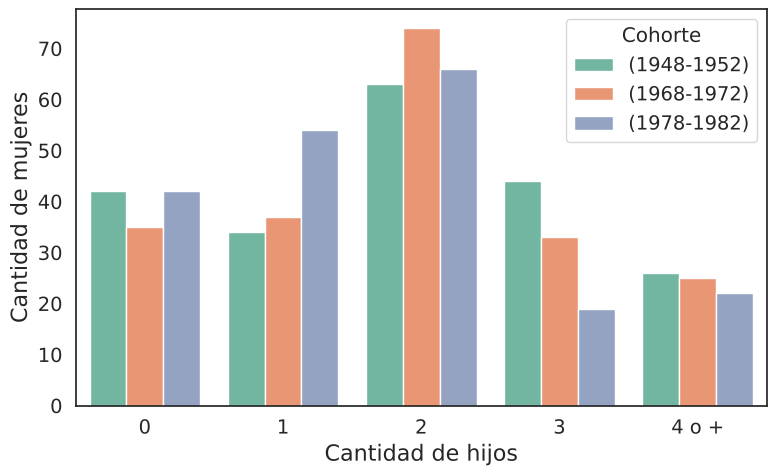

In [43]:
# Figura 2: distribución de cantidad de hijos, por mujer y cohorte
counts_fig = (women.groupby(['cohorte_label', 'children_categories'], observed=True).size()
              .reset_index(name='Cantidad de mujeres'))

plt.figure(figsize=(8, 5))
sns.barplot(data=counts_fig, x='children_categories', y='Cantidad de mujeres', hue='cohorte_label',
            hue_order=cohorte_order, order=hijos_order)
plt.xlabel('Cantidad de hijos', fontsize=16)
plt.ylabel('Cantidad de mujeres', fontsize=16)
plt.legend(title='Cohorte', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
guardar('figura_02_hijos_por_cohorte.png')

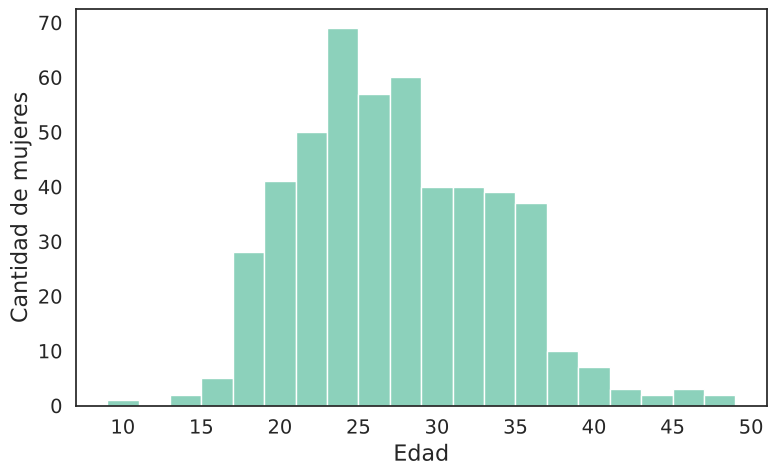

In [44]:
# Figura 3: distribución de la edad de la primera maternidad
plt.figure(figsize=(8, 5))
sns.histplot(women['age_motherhood'], bins=20, kde=False, color=sns.color_palette(PALETA)[0])
plt.xlabel('Edad', fontsize=16)
plt.ylabel('Cantidad de mujeres', fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
guardar('figura_03_edad_primera_maternidad.png')

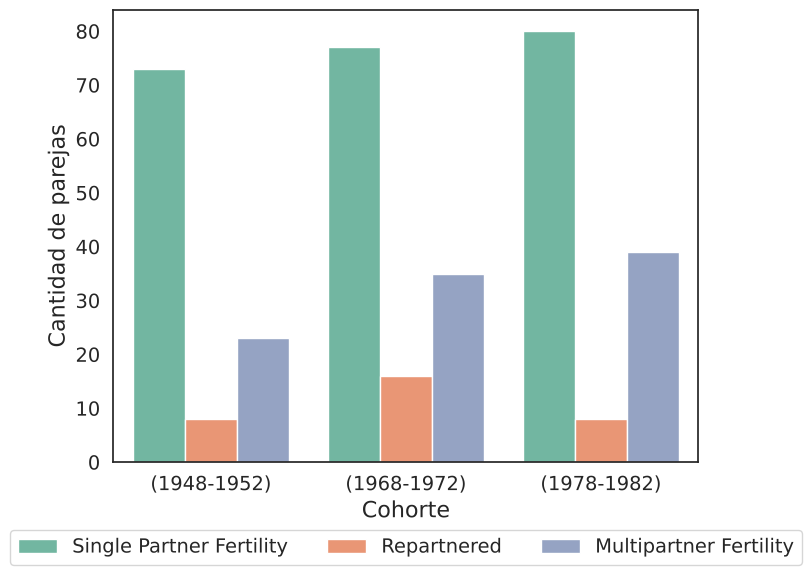

In [45]:
# Figura 4: cantidad de parejas con hijos, por cohorte e historia de vida
parejas_historia_cohorte = (parents.groupby('cohorte_label', observed=True)[['single_partner', 'repartnered', 'multipartner_fertility']]
                            .sum().reset_index()
                            .melt(id_vars='cohorte_label', var_name='life_story', value_name='Cantidad de parejas'))
parejas_historia_cohorte['Historia de vida'] = parejas_historia_cohorte['life_story'].map(
    {'single_partner': 'Single Partner Fertility', 'repartnered': 'Repartnered', 'multipartner_fertility': 'Multipartner Fertility'})

plt.figure(figsize=(8, 6))
sns.barplot(data=parejas_historia_cohorte, x='cohorte_label', y='Cantidad de parejas', hue='Historia de vida',
            hue_order=historia_order, order=cohorte_order)
plt.xlabel('Cohorte', fontsize=16)
plt.ylabel('Cantidad de parejas', fontsize=16)
plt.legend(fontsize=14, bbox_to_anchor=(0.5, -0.15), loc='upper center', ncol=3, borderaxespad=0)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
guardar('figura_04_parejas_historia_vida.png')

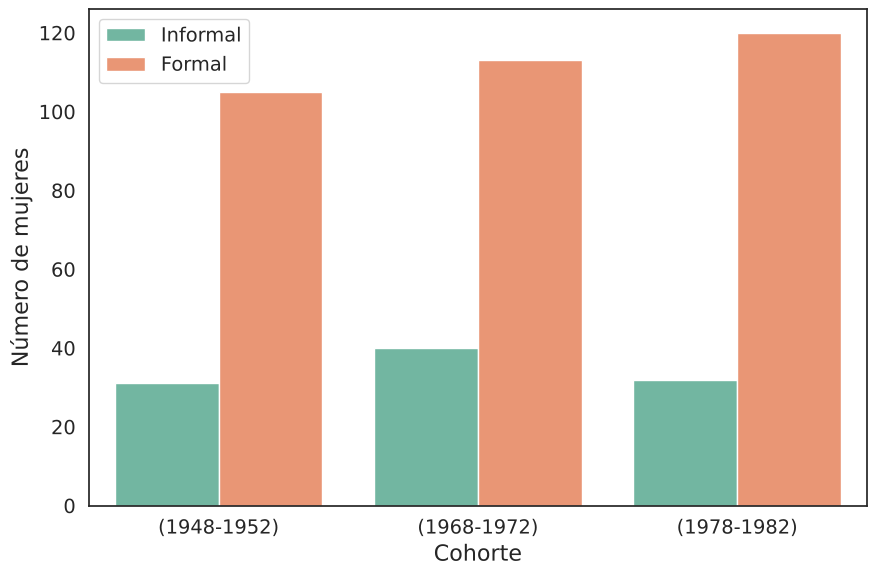

In [46]:
# Figura 5: cantidad de mujeres, por cohorte y condición laboral
counts_fig = (workers.groupby(['cohorte_label', 'informality_label'], observed=True)['individual_id'].nunique()
              .reset_index().rename(columns={'individual_id': 'n_mujeres'}))

plt.figure(figsize=(9, 6))
sns.barplot(data=counts_fig, x='cohorte_label', y='n_mujeres', hue='informality_label',
            hue_order=informality_order, order=cohorte_order)
plt.xlabel('Cohorte', fontsize=16)
plt.ylabel('Número de mujeres', fontsize=16)
plt.legend(fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
guardar('figura_05_informalidad_por_cohorte.png')

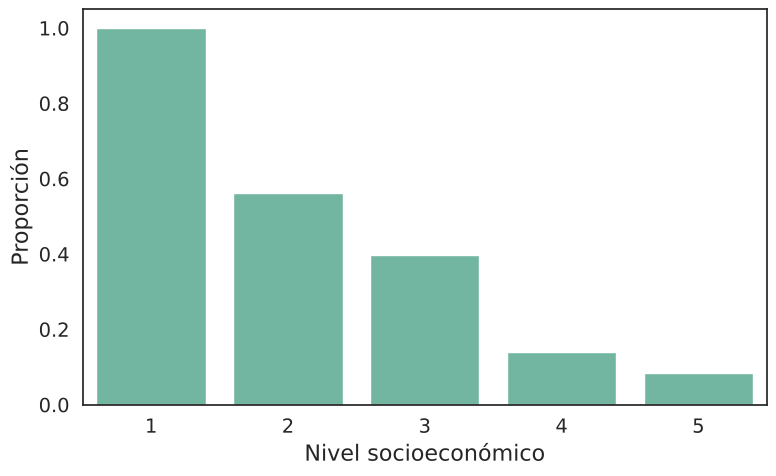

In [47]:
# Figura 6: probabilidad de informalidad por nivel socioeconómico
plt.figure(figsize=(8, 5))
sns.barplot(data=workers, x='status', y='informality', estimator='mean', errorbar=None, color=sns.color_palette(PALETA)[0])
plt.xlabel('Nivel socioeconómico', fontsize=16)
plt.ylabel('Proporción', fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
guardar('figura_06_informalidad_por_nse.png')

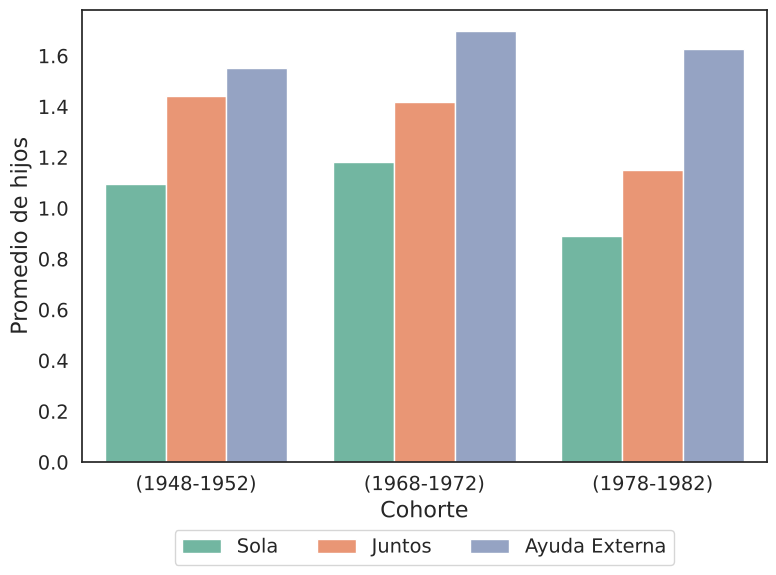

In [48]:
# Figura 7: promedio de hijos por pareja, por división de tareas y cohorte
plt.figure(figsize=(8, 6))
sns.barplot(data=workers, x='cohorte_label', y='children_total', hue='hh_work_label', hue_order=distribution_order,
            order=cohorte_order, estimator='mean', errorbar=None)
plt.xlabel('Cohorte', fontsize=16)
plt.ylabel('Promedio de hijos', fontsize=16)
plt.legend(fontsize=14, bbox_to_anchor=(0.5, -0.15), loc='upper center', ncol=3, borderaxespad=0)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
guardar('figura_07_hijos_tareas_cohorte.png')

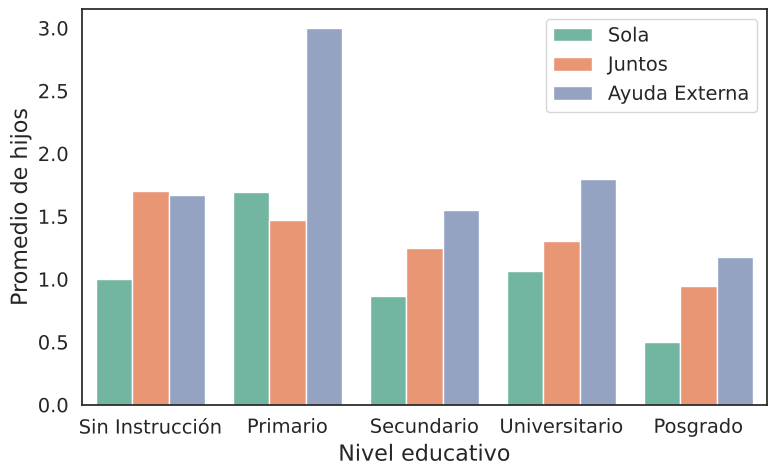

In [49]:
# Figura 8: promedio de hijos por pareja, por división de tareas y nivel educativo
plt.figure(figsize=(8, 5))
sns.barplot(data=workers, x='education_label', y='children_total', hue='hh_work_label', hue_order=distribution_order,
            order=education_order, estimator='mean', errorbar=None)
plt.xlabel('Nivel educativo', fontsize=16)
plt.ylabel('Promedio de hijos', fontsize=16)
plt.legend(fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
guardar('figura_08_hijos_tareas_educacion.png')

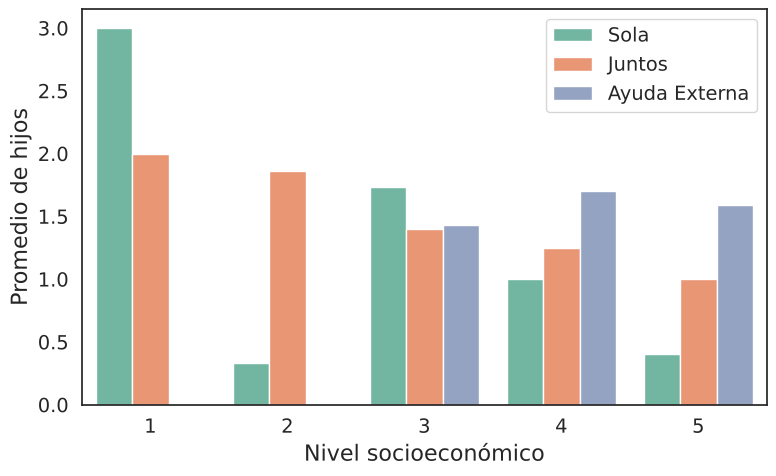

In [50]:
# Figura 9: promedio de hijos por pareja, por división de tareas y nivel socioeconómico
plt.figure(figsize=(8, 5))
sns.barplot(data=workers, x='status', y='children_total', hue='hh_work_label', hue_order=distribution_order,
            estimator='mean', errorbar=None)
plt.xlabel('Nivel socioeconómico', fontsize=16)
plt.ylabel('Promedio de hijos', fontsize=16)
plt.legend(fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
guardar('figura_09_hijos_tareas_nse.png')

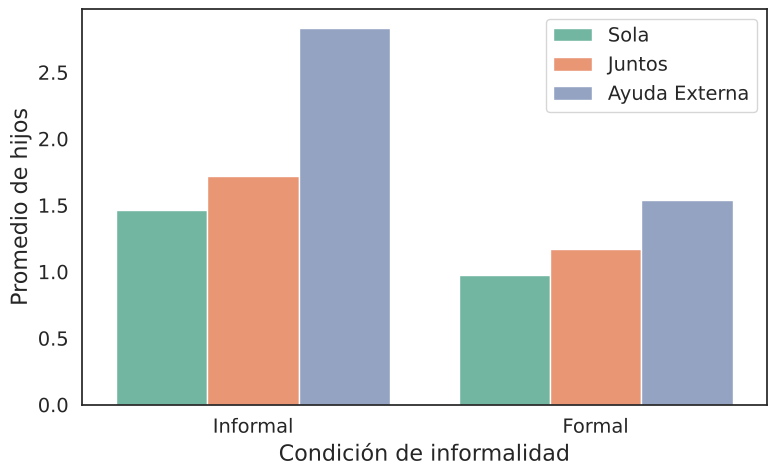

In [51]:
# Figura 10: promedio de hijos por pareja, por división de tareas y condición laboral
plt.figure(figsize=(8, 5))
sns.barplot(data=workers, x='informality_label', y='children_total', hue='hh_work_label', hue_order=distribution_order,
            order=informality_order, estimator='mean', errorbar=None)
plt.xlabel('Condición de informalidad', fontsize=16)
plt.ylabel('Promedio de hijos', fontsize=16)
plt.legend(fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
guardar('figura_10_hijos_tareas_informalidad.png')

Matriz de transición (cantidad de parejas):
post_mode      Sola  Juntos  Ayuda Externa
pre_mode                                  
Sola             25      11              5
Juntos            1     218             11
Ayuda Externa     1       8             37
Matriz de transición (proporciones por fila):
post_mode       Sola  Juntos  Ayuda Externa
pre_mode                                   
Sola           0.610   0.268          0.122
Juntos         0.004   0.948          0.048
Ayuda Externa  0.022   0.174          0.804


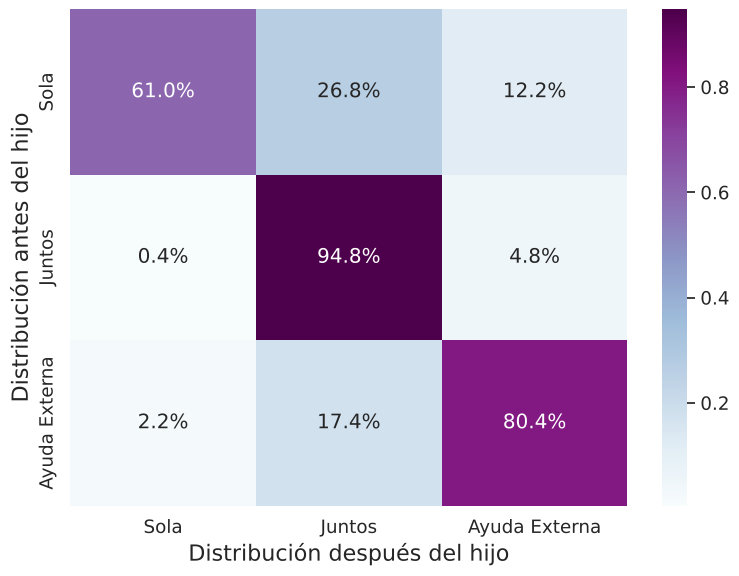

In [52]:
# Figura 11: matriz de transición de la división de tareas (antes vs. después del primer hijo)
orden = ['Sola', 'Juntos', 'Ayuda Externa']
transition_counts = pd.crosstab(workers['pre_mode'].map(hh_labels), workers['post_mode'].map(hh_labels)).reindex(index=orden, columns=orden)
transition_matrix = pd.crosstab(workers['pre_mode'].map(hh_labels), workers['post_mode'].map(hh_labels),
                                normalize='index').reindex(index=orden, columns=orden)
report('Matriz de transición (cantidad de parejas):\n' + transition_counts.to_string())
report('Matriz de transición (proporciones por fila):\n' + transition_matrix.round(3).to_string())

plt.figure(figsize=(8, 6))
sns.heatmap(transition_matrix, annot=True, fmt='.1%', cmap='BuPu', cbar=True)
plt.ylabel('Distribución antes del hijo', fontsize=16)
plt.xlabel('Distribución después del hijo', fontsize=16)
guardar('figura_11_matriz_transicion.png')

Promedio de división de tareas pre y post primer hijo, por nivel socioeconómico:
        pre_mean  post_mean
status                     
1          1.869      1.881
2          1.919      1.988
3          1.900      1.913
4          2.023      2.077
5          2.253      2.291


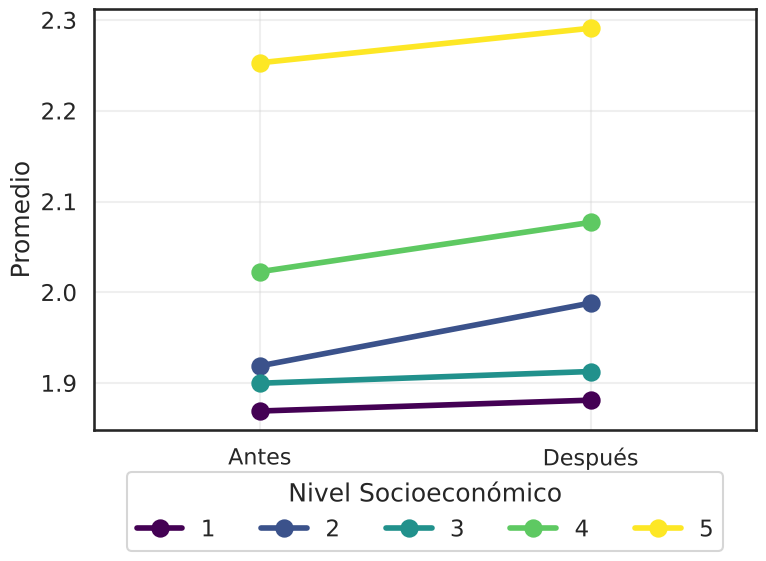

In [53]:
# Figura 12: trayectoria del promedio de trabajo doméstico (1 = Sola, 2 = Juntos, 3 = Ayuda externa), pre vs. post hijo
df_slope = workers_panel.melt(id_vars=['status'], value_vars=['pre_mean', 'post_mean'], var_name='momento', value_name='hh_work_score')
report('Promedio de división de tareas pre y post primer hijo, por nivel socioeconómico:\n' +
       workers_panel.groupby('status')[['pre_mean', 'post_mean']].mean().round(3).to_string())

with sns.plotting_context('talk'):
    plt.figure(figsize=(8, 6))
    sns.pointplot(data=df_slope, x='momento', y='hh_work_score', hue='status', palette='viridis', errorbar=None)
    plt.ylabel('Promedio')
    plt.xlabel('')
    plt.xticks(ticks=[0, 1], labels=['Antes', 'Después'], fontsize=16)
    plt.legend(title='Nivel Socioeconómico', bbox_to_anchor=(0.5, -0.1), loc='upper center', ncol=5, borderaxespad=0)
    plt.grid(True, alpha=0.3)
    guardar('figura_12_trayectoria_tareas_nse.png')

Último empleo pre maternidad (% por fila):
job_type    Formal  Informal
left_label                  
No            68.0      32.0
Sí            57.1      42.9


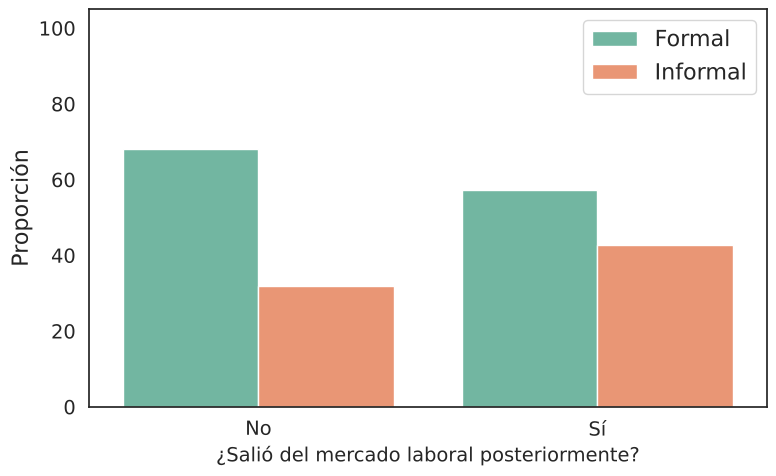

In [54]:
# Figura 13: condición laboral en el último empleo pre maternidad, según si luego salió del mercado laboral
plot_data = (last_jobs_df.assign(left_label=last_jobs_df['left_market'].map(yes_no_labels),
                                 job_type=last_jobs_df['informality'].map(job_type_labels))
             .groupby(['left_label', 'job_type']).size().reset_index(name='Cantidad'))
plot_data['Porcentaje (%)'] = plot_data.groupby('left_label')['Cantidad'].transform(lambda x: 100 * x / x.sum())
report('Último empleo pre maternidad (% por fila):\n' + plot_data.pivot(index='left_label', columns='job_type', values='Porcentaje (%)').round(1).to_string())

plt.figure(figsize=(8, 5))
sns.barplot(data=plot_data, x='left_label', y='Porcentaje (%)', hue='job_type', hue_order=['Formal', 'Informal'],
            order=yes_no_order, palette=PALETA)
plt.xlabel('¿Salió del mercado laboral posteriormente?', fontsize=14)
plt.ylabel('Proporción', fontsize=16)
plt.legend(loc='upper right', fontsize=16)
plt.ylim(0, 105)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
guardar('figura_13_ultimo_empleo_pre_maternidad.png')

Primer empleo post maternidad (% por fila):
Condición laboral  Formal  Informal
Salió del mercado                  
No                   71.0      29.0
Sí                   61.1      38.9


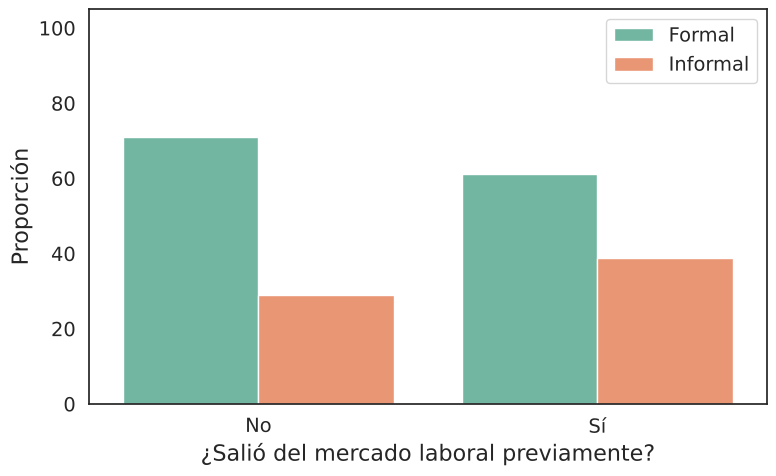

In [55]:
# Figura 14: tipo de primer empleo post maternidad, según si salió del mercado laboral
counts = first_jobs.groupby(['left_market', 'informality'], observed=True).size().reset_index(name='Cantidad')
counts['Proporción (%)'] = counts.groupby('left_market')['Cantidad'].transform(lambda x: 100 * x / x.sum())
counts['Condición laboral'] = counts['informality'].map(job_type_labels)
counts['Salió del mercado'] = counts['left_market'].map(yes_no_labels)
report('Primer empleo post maternidad (% por fila):\n' + counts.pivot(index='Salió del mercado', columns='Condición laboral', values='Proporción (%)').round(1).to_string())

plt.figure(figsize=(8, 5))
sns.barplot(data=counts, x='Salió del mercado', y='Proporción (%)', hue='Condición laboral', hue_order=['Formal', 'Informal'],
            order=yes_no_order, palette=PALETA)
plt.ylabel('Proporción', fontsize=16)
plt.xlabel('¿Salió del mercado laboral previamente?', fontsize=16)
plt.legend(loc='upper right', fontsize=14)
plt.ylim(0, 105)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
guardar('figura_14_primer_empleo_post_maternidad.png')

In [56]:
# guardamos las estadísticas descriptivas
(OUT_TAB / 'estadisticas_descriptivas.txt').write_text('\n\n'.join(lines), encoding='utf-8')

2492